In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.cm as cm
import matplotlib.ticker as ticker


In [2]:
def import_data(file_path):

    data = pd.read_csv(file_path, comment='!', sep=',')
    data = data.rename(columns=lambda x: x.strip())
    headers = data.columns.tolist()
    return data, headers



In [3]:
calibration_path = 'B_curr_calibration_05-03-2026.csv'

calibration_data, headers = import_data(calibration_path)

print(headers)
print(calibration_data.head())

['H(y) (T)', 'Error H(y) (T)', 'Current (A)', 'Actual Current (A)']
   H(y) (T)  Error H(y) (T)  Current (A)  Actual Current (A)
0 -0.000070        0.000193         0.01               0.000
1  0.000358        0.000033         0.02               0.022
2  0.000577        0.000034         0.03               0.031
3  0.000792        0.000033         0.04               0.031
4  0.001010        0.000033         0.05               0.031


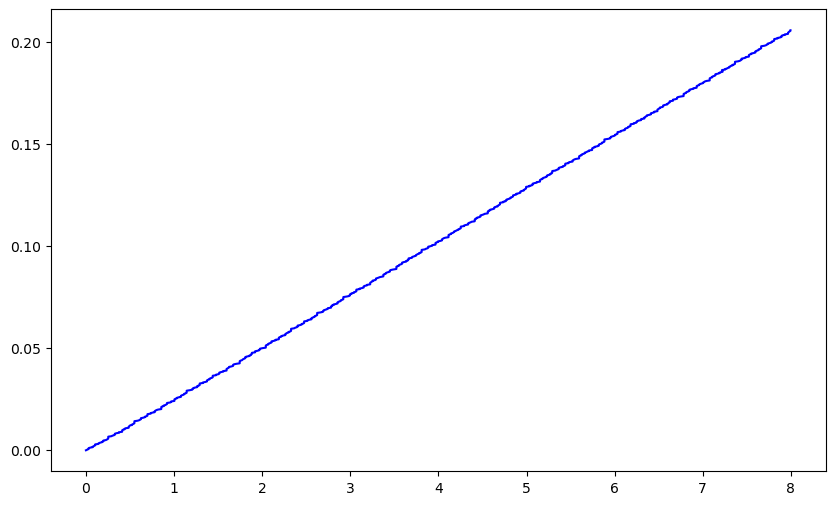

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))


ax.plot(calibration_data[headers[3]], calibration_data[headers[0]], label='current difference', color='blue')


In [27]:
from pathlib import Path


def calculate_trendline(x, y, fit_type='linear'):
    """
    Function to calculate the trendline for the given data.
    Args:
        x (pd.Series): X-axis data.
        y (pd.Series): Y-axis data.
    Returns:
        slope and intercept to generate trendline.
    """
    if fit_type == 'linear':
        slope, intercept = np.polyfit(x, y, 1)
        # trendline = slope * x + intercept
        print(f'slope:{slope} and y intercept:{intercept}')
        return slope, intercept

In [17]:
m, c = calculate_trendline(calibration_data[headers[3]], calibration_data[headers[0]]*1e3, fit_type='linear')

slope:25.87856325385384 and y intercept:-1.2956896228150494


0.00236698T field at 0.105A
magnetic field per unit current: 25.88 mT/A


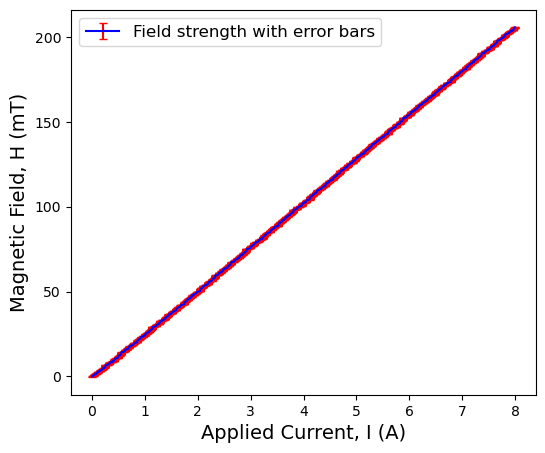

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))


# ax.plot(calibration_data[headers[3]], calibration_data[headers[0]]*1e3, label='field', color='red')

ax.errorbar(calibration_data[headers[3]], calibration_data[headers[0]]*1e3, yerr=2*calibration_data[headers[1]]*1e3, fmt='-',capsize = 3,ecolor = "red", label='Field strength with error bars', color='blue')
# ax.plot(calibration_data[headers[3]], m*calibration_data[headers[3]] + c, label=f'Linear fit: H = {m:.2f}  + {c:.2f}', color='orange', linestyle='--')

print(f'{calibration_data[headers[0]].iloc[10]}T field at {calibration_data[headers[3]].iloc[10]}A')
print(f'magnetic field per unit current: {m:.2f} mT/A')

ax.set_xlabel("Applied Current, I (A)", fontsize=14)

ax.set_ylabel("Magnetic Field, H (mT)", fontsize=14)


ax.legend(fontsize=12, loc="upper left")



SAVE_FOLDER = 'C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\Masters Project\\Results\\Experiments\\Spectrum_analyser_iMNS\\Plots\\'
save_path = Path(f'{SAVE_FOLDER}\\B-curr-calibration.svg')

fig.savefig(
    save_path,
    format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
    dpi=300,
    bbox_inches="tight"
    )
